In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

import joblib

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [3]:
df = pd.read_csv("dataset/Wholesale customers data.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [5]:
print("Shape:")
print(df.shape)



Shape:
(440, 8)


In [6]:
print("\nColumns:")
print(df.columns.tolist())


Columns:
['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


In [7]:
print("\nData types:")
print(df.dtypes)


Data types:
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object


In [8]:
print("\nInformation:")
df.info()


Information:
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [9]:
print("\nStatistical summary:")
df.describe()


Statistical summary:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [10]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


In [11]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [12]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (440, 8)


In [17]:
spending_features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

X = df[spending_features]

print("Spending features:")
print(X.head())

Spending features:
   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0  12669  9656     7561     214              2674        1338
1   7057  9810     9568    1762              3293        1776
2   6353  8808     7684    2405              3516        7844
3  13265  1196     4221    6404               507        1788
4  22615  5410     7198    3915              1777        5185


In [14]:
X.describe()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [18]:
print("Skewness:")
print(X.skew().sort_values(ascending=False))

Skewness:
Delicassen          11.151586
Frozen               5.907986
Milk                 4.053755
Detergents_Paper     3.631851
Grocery              3.587429
Fresh                2.561323
dtype: float64


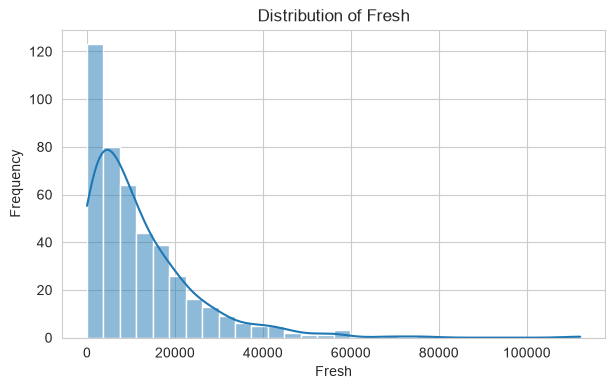

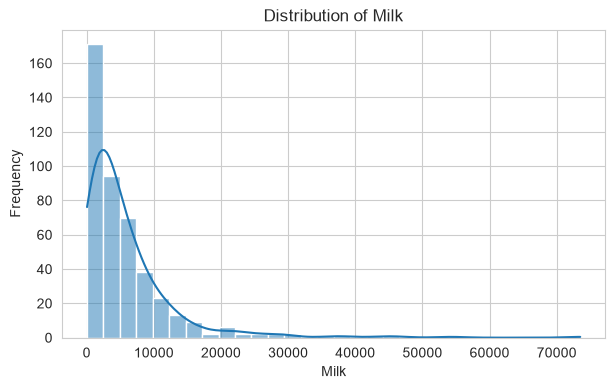

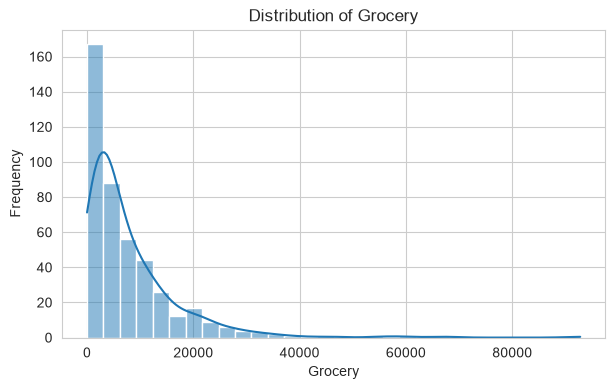

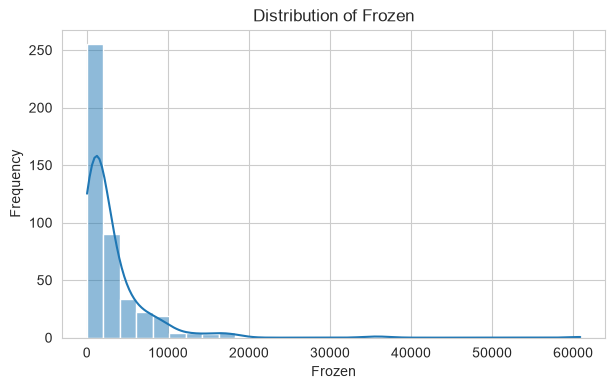

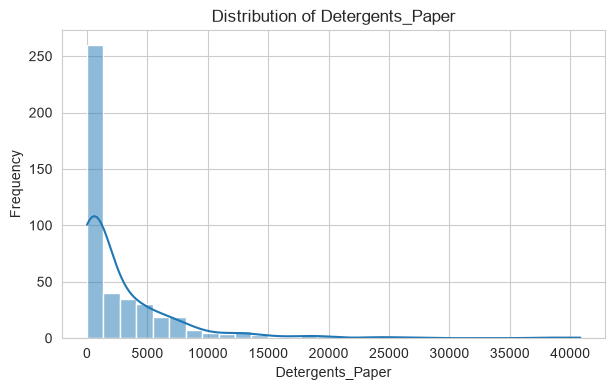

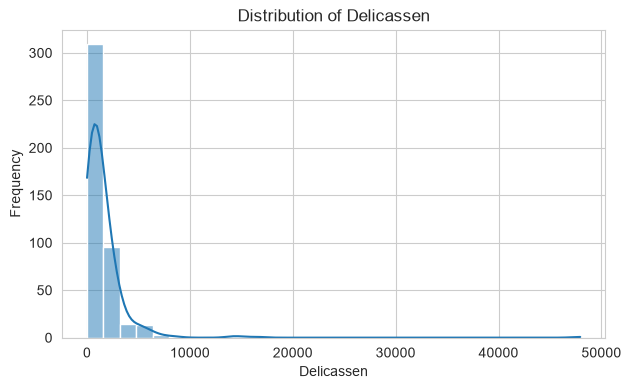

In [19]:
for column in spending_features:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        df[column],
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.show()

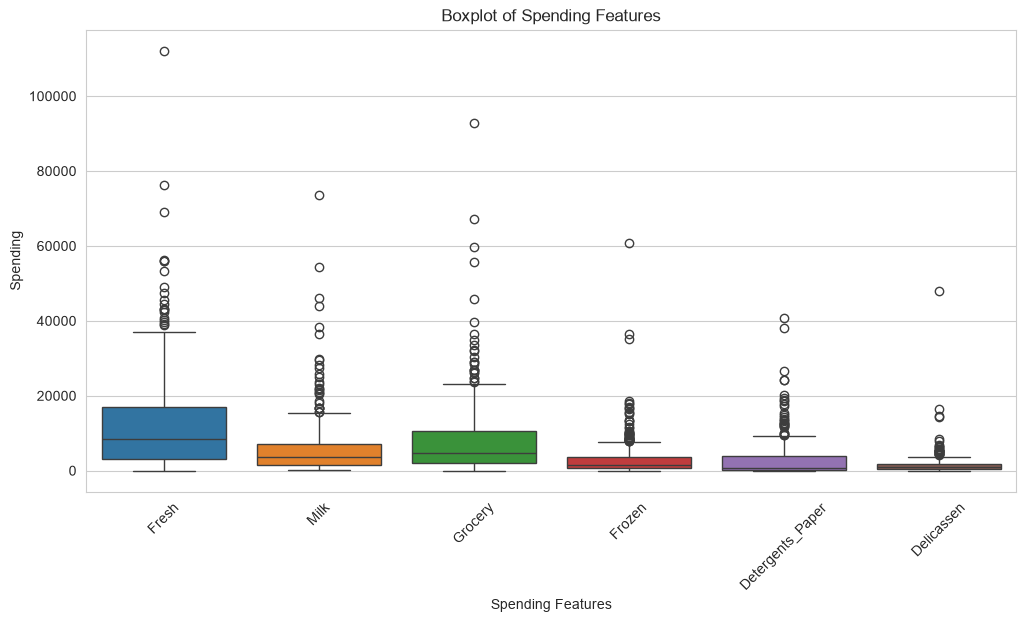

In [20]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=X)

plt.title("Boxplot of Spending Features")
plt.xlabel("Spending Features")
plt.ylabel("Spending")

plt.xticks(rotation=45)

plt.show()

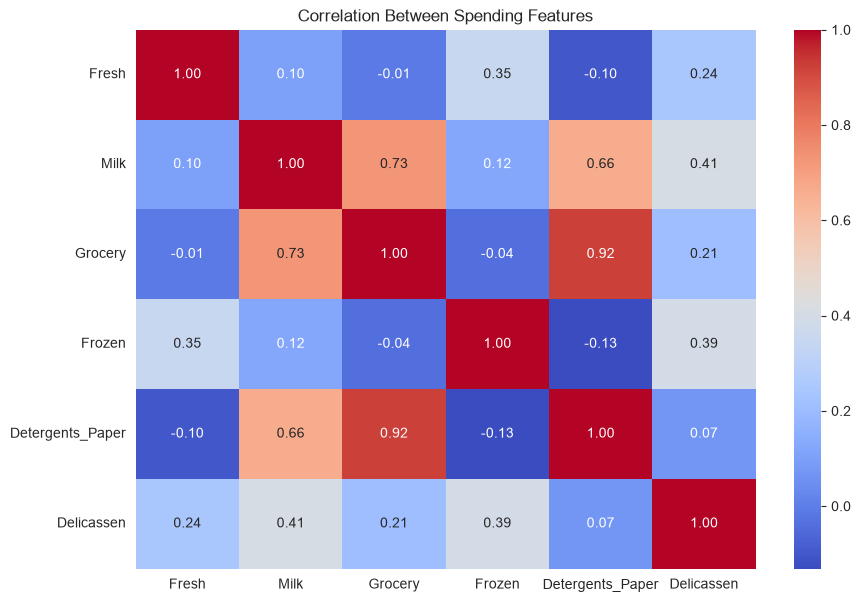

In [21]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Spending Features")

plt.show()

In [22]:
X_log = np.log1p(X)

In [23]:
X_log.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,9.446992,9.175438,8.930891,5.370638,7.891705,7.199678
1,8.861917,9.191259,9.166284,7.474772,8.099858,7.482682
2,8.756840,9.083529,8.947026,7.785721,8.165364,8.967632
3,9.492960,7.087574,8.348064,8.764834,6.230481,7.489412
4,10.026413,8.596189,8.881697,8.272826,7.483244,8.553718


In [24]:
skewness_comparison = pd.DataFrame({
    "Before_Log": X.skew(),
    "After_Log": X_log.skew()
})

skewness_comparison

,Before_Log,After_Log
Fresh,2.561323,-1.575326
Milk,4.053755,-0.224063
Grocery,3.587429,-0.674938
Frozen,5.907986,-0.352655
Detergents_Paper,3.631851,-0.235961
Delicassen,11.151586,-1.091827


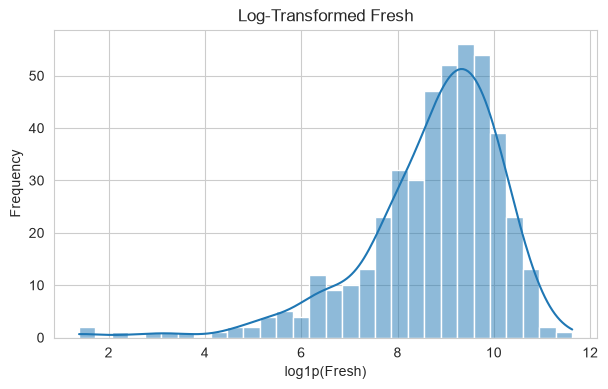

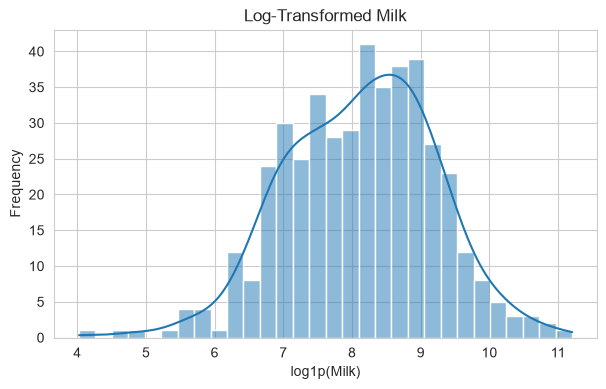

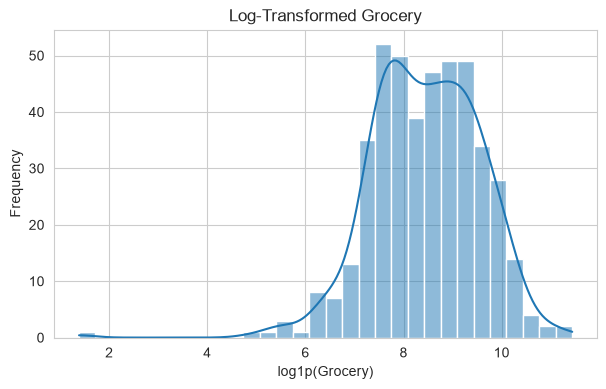

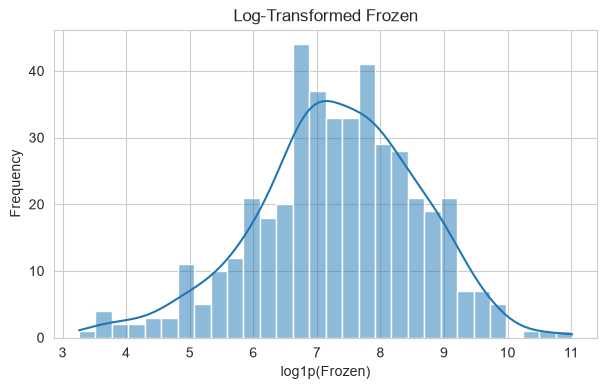

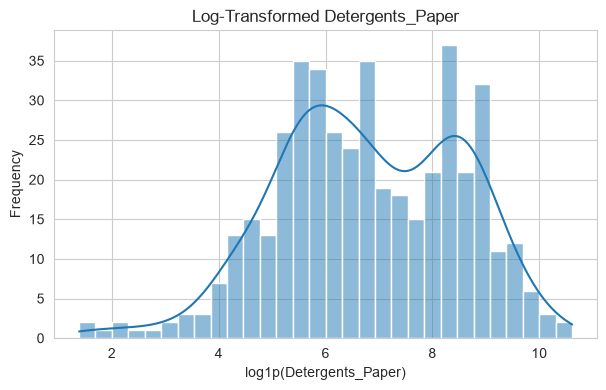

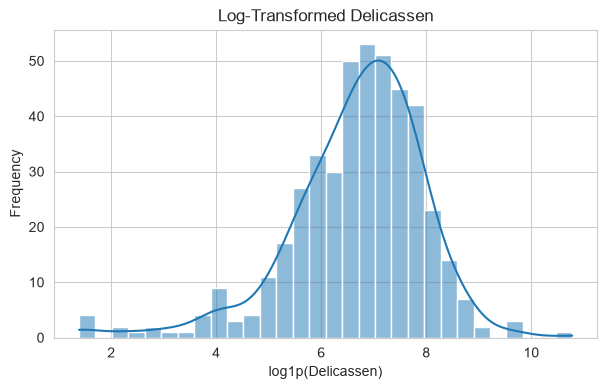

In [25]:
for column in spending_features:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        X_log[column],
        bins=30,
        kde=True
    )

    plt.title(f"Log-Transformed {column}")
    plt.xlabel(f"log1p({column})")
    plt.ylabel("Frequency")

    plt.show()

In [26]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=spending_features
)

X_scaled.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.486184,0.976299,0.440155,-1.509250,0.644143,0.408966
1,0.087889,0.990956,0.652171,0.134052,0.766043,0.627926
2,0.016356,0.891151,0.454687,0.376899,0.804405,1.776833
3,0.517477,-0.957973,-0.084792,1.141574,-0.328712,0.633133
4,0.880631,0.439662,0.395847,0.757322,0.404939,1.456588


In [27]:
print("Means:")
print(X_scaled.mean())

print("\nStandard deviations:")
print(X_scaled.std())

Means:
Fresh               3.229740e-17
Milk               -7.105427e-16
Grocery            -1.081963e-15
Frozen              2.987509e-16
Detergents_Paper   -6.297992e-16
Delicassen         -2.220446e-17
dtype: float64

Standard deviations:
Fresh               1.001138
Milk                1.001138
Grocery             1.001138
Frozen              1.001138
Detergents_Paper    1.001138
Delicassen          1.001138
dtype: float64


In [28]:
inertia = []

K = range(2, 11)

for k in K:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

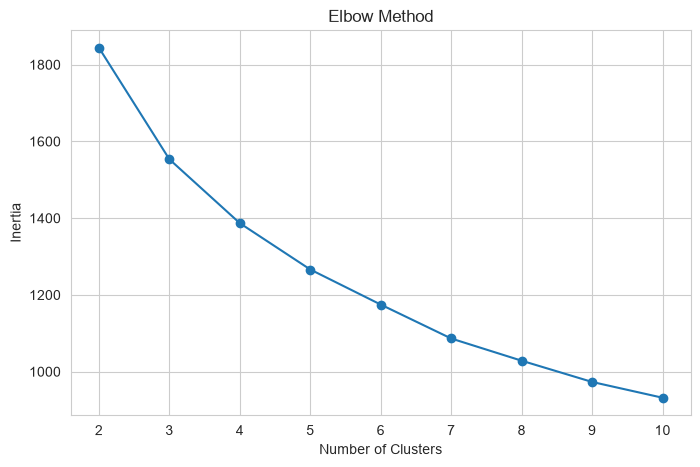

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    K,
    inertia,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.xticks(K)

plt.show()

In [30]:
silhouette_scores = []

for k in K:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

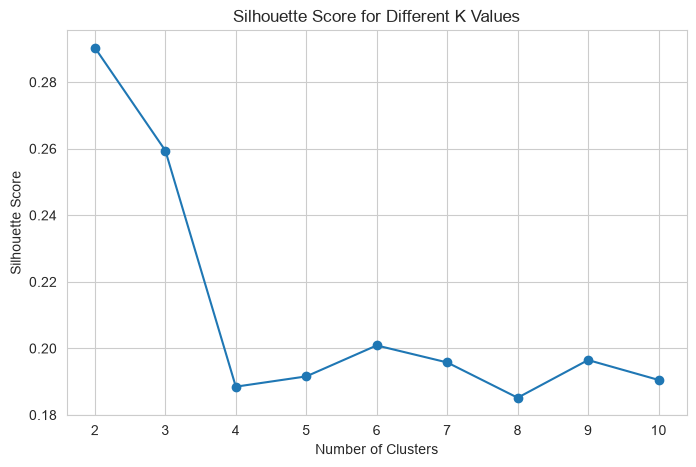

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(
    K,
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.xticks(K)

plt.show()

In [32]:
cluster_selection = pd.DataFrame({
    "K": list(K),
    "Inertia": inertia,
    "Silhouette_Score": silhouette_scores
})

cluster_selection

,K,Inertia,Silhouette_Score
0,2,1844.064069,0.290328
1,3,1553.421327,0.259416
2,4,1386.862741,0.188495
3,5,1266.149362,0.191585
4,6,1174.758633,0.200887
5,7,1086.358700,0.195780
6,8,1028.486217,0.185175
7,9,973.141483,0.196501
8,10,931.998464,0.190523


In [33]:
FINAL_K = 3

In [34]:
kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

df["KMeans_Cluster"] = kmeans_labels

In [35]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,2
4,2,3,22615,5410,7198,3915,1777,5185,1


In [36]:
kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)

print("K-Means Silhouette Score:",
      round(kmeans_silhouette, 4))

K-Means Silhouette Score: 0.2594


In [37]:
kmeans_db = davies_bouldin_score(
    X_scaled,
    kmeans_labels
)

print("K-Means Davies-Bouldin Index:",
      round(kmeans_db, 4))

K-Means Davies-Bouldin Index: 1.3406


In [38]:
cluster_counts = (
    df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

print(cluster_counts)

KMeans_Cluster
0     80
1    147
2    213
Name: count, dtype: int64


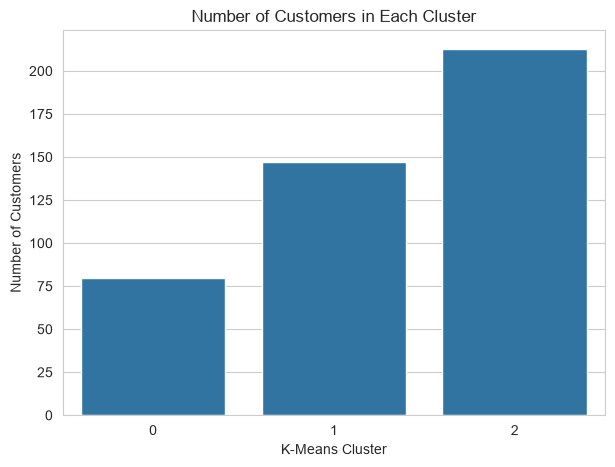

In [39]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("K-Means Cluster")
plt.ylabel("Number of Customers")

plt.show()

In [40]:
cluster_profile = (
    df.groupby("KMeans_Cluster")[spending_features]
    .mean()
)

cluster_profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,
0,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500
1,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837
2,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977


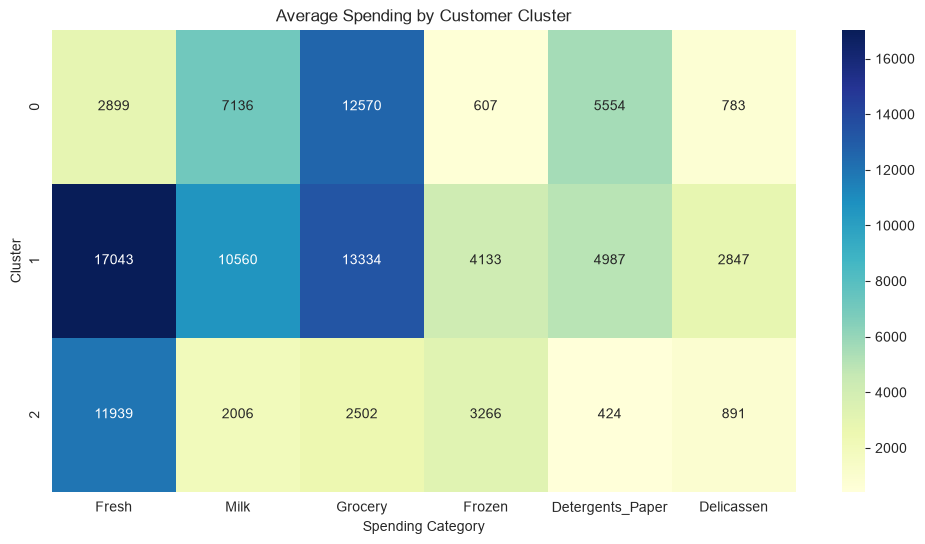

In [41]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_profile,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Average Spending by Customer Cluster")
plt.xlabel("Spending Category")
plt.ylabel("Cluster")

plt.show()

In [42]:
cluster_profile_scaled = pd.DataFrame(
    StandardScaler().fit_transform(cluster_profile),
    columns=spending_features,
    index=cluster_profile.index
)

cluster_profile_scaled

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,
0,-1.321405,0.161822,0.628312,-1.374245,0.827043,-0.763554
1,1.097069,1.135790,0.783076,0.976239,0.579958,1.412669
2,0.224336,-1.297611,-1.411388,0.398006,-1.407000,-0.649116


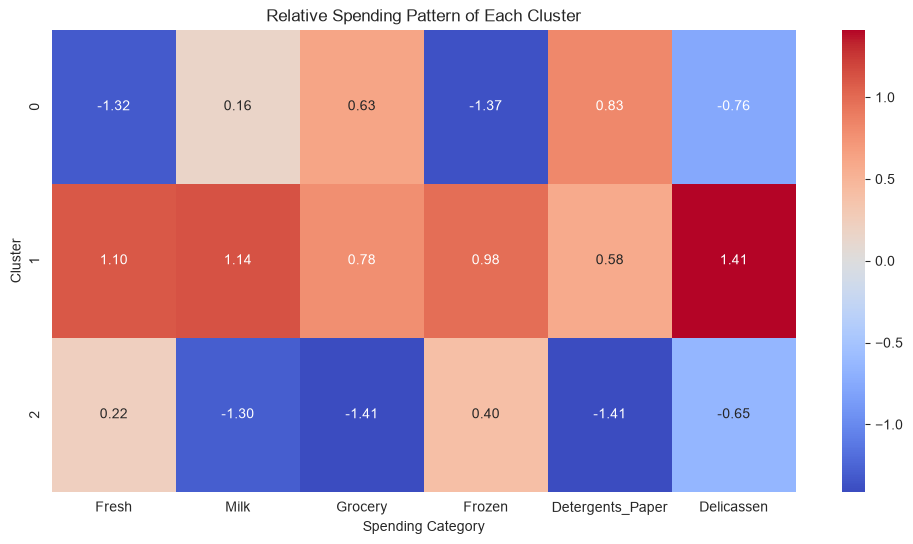

In [43]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_profile_scaled,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Relative Spending Pattern of Each Cluster")
plt.xlabel("Spending Category")
plt.ylabel("Cluster")

plt.show()

In [44]:
for cluster in cluster_profile.index:

    highest = cluster_profile.loc[cluster].idxmax()
    lowest = cluster_profile.loc[cluster].idxmin()

    print(f"\nCluster {cluster}")
    print("Highest spending category:", highest)
    print("Lowest spending category:", lowest)


Cluster 0
Highest spending category: Grocery
Lowest spending category: Frozen

Cluster 1
Highest spending category: Fresh
Lowest spending category: Delicassen

Cluster 2
Highest spending category: Fresh
Lowest spending category: Detergents_Paper


In [45]:
cluster_summary = cluster_profile.copy()

cluster_summary["Customer_Count"] = (
    df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

cluster_summary["Highest_Category"] = (
    cluster_profile.idxmax(axis=1)
)

cluster_summary["Lowest_Category"] = (
    cluster_profile.idxmin(axis=1)
)

cluster_summary

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Customer_Count,Highest_Category,Lowest_Category
KMeans_Cluster,,,,,,,,,
0,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500,80,Grocery,Frozen
1,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837,147,Fresh,Delicassen
2,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977,213,Fresh,Detergents_Paper


In [46]:
cluster_names = {
    0: "Cluster 0",
    1: "Cluster 1",
    2: "Cluster 2"
}

df["Customer_Segment"] = (
    df["KMeans_Cluster"]
    .map(cluster_names)
)

In [47]:
cluster_names = {
    0: "High Grocery and Detergents Customers",
    1: "Fresh Product Customers",
    2: "Moderate Spending Customers"
}

df["Customer_Segment"] = (
    df["KMeans_Cluster"]
    .map(cluster_names)
)

In [48]:
agglomerative = AgglomerativeClustering(
    n_clusters=FINAL_K,
    linkage="ward"
)

agg_labels = agglomerative.fit_predict(X_scaled)

df["Agglomerative_Cluster"] = agg_labels

In [49]:
agg_silhouette = silhouette_score(
    X_scaled,
    agg_labels
)

agg_db = davies_bouldin_score(
    X_scaled,
    agg_labels
)

print(
    "Agglomerative Silhouette Score:",
    round(agg_silhouette, 4)
)

print(
    "Agglomerative Davies-Bouldin Index:",
    round(agg_db, 4)
)

Agglomerative Silhouette Score: 0.2547
Agglomerative Davies-Bouldin Index: 1.539


In [50]:
comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Agglomerative"
    ],
    
    "Silhouette Score": [
        kmeans_silhouette,
        agg_silhouette
    ],
    
    "Davies-Bouldin Index": [
        kmeans_db,
        agg_db
    ]
})

comparison

,Algorithm,Silhouette Score,Davies-Bouldin Index
0,K-Means,0.259416,1.340563
1,Agglomerative,0.254657,1.538995


In [51]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

In [52]:
print("PC1 variance:",
      round(pca.explained_variance_ratio_[0] * 100, 2),
      "%")

print("PC2 variance:",
      round(pca.explained_variance_ratio_[1] * 100, 2),
      "%")

print("Total variance explained:",
      round(pca.explained_variance_ratio_.sum() * 100, 2),
      "%")

PC1 variance: 44.08 %
PC2 variance: 27.19 %
Total variance explained: 71.27 %


In [53]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = kmeans_labels

pca_df.head()

,PC1,PC2,Cluster
0,1.380383,-0.304727,1
1,1.438870,0.537468,1
2,1.513453,1.232565,1
3,-0.825105,1.210790,2
4,0.802897,1.766046,1


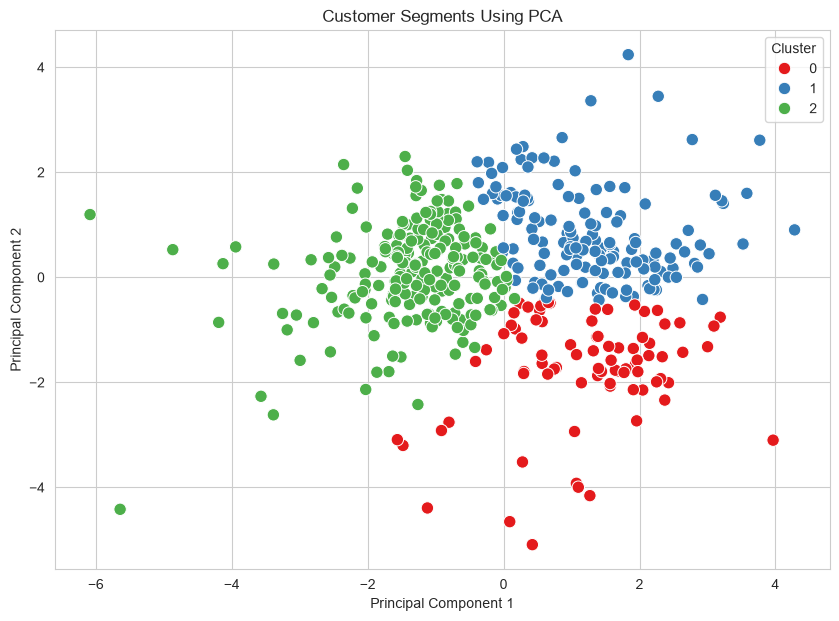

In [54]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=80
)

plt.title("Customer Segments Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(title="Cluster")

plt.show()

In [55]:
pca_loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=spending_features
)

pca_loadings

,PC1,PC2
Fresh,-0.105250,0.590359
Milk,0.542329,0.132911
Grocery,0.571472,-0.005751
Frozen,-0.137910,0.589778
Detergents_Paper,0.550642,-0.070822
Delicassen,0.214469,0.530022


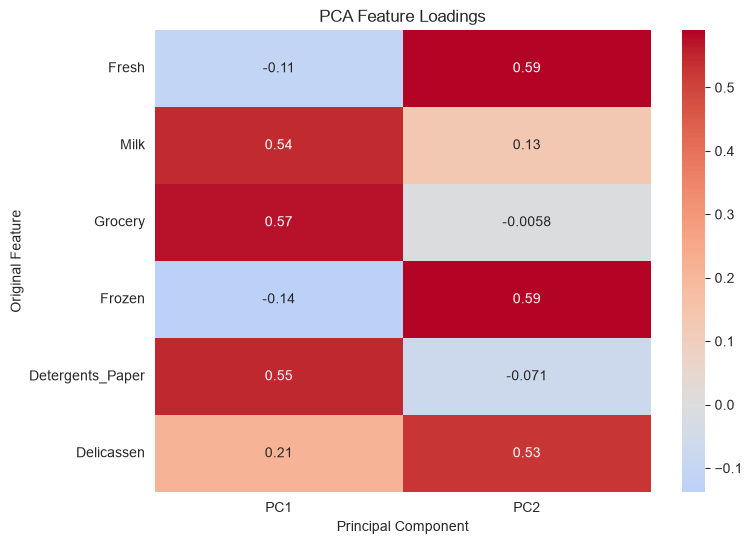

In [56]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    pca_loadings,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("PCA Feature Loadings")
plt.xlabel("Principal Component")
plt.ylabel("Original Feature")

plt.show()

In [57]:
channel_analysis = pd.crosstab(
    df["KMeans_Cluster"],
    df["Channel"]
)

channel_analysis

Channel,1,2
KMeans_Cluster,,
0,32,48
1,56,91
2,210,3


In [58]:
channel_percentage = pd.crosstab(
    df["KMeans_Cluster"],
    df["Channel"],
    normalize="index"
) * 100

channel_percentage.round(2)

Channel,1,2
KMeans_Cluster,,
0,40.00,60.00
1,38.10,61.90
2,98.59,1.41


In [59]:
region_analysis = pd.crosstab(
    df["KMeans_Cluster"],
    df["Region"]
)

region_analysis

Region,1,2,3
KMeans_Cluster,,,
0,14,10,56
1,23,11,113
2,40,26,147


In [60]:
region_percentage = pd.crosstab(
    df["KMeans_Cluster"],
    df["Region"],
    normalize="index"
) * 100

region_percentage.round(2)

Region,1,2,3
KMeans_Cluster,,,
0,17.50,12.50,70.00
1,15.65,7.48,76.87
2,18.78,12.21,69.01


In [61]:
final_summary = df.groupby("KMeans_Cluster").agg(
    Customer_Count=("KMeans_Cluster", "size"),
    Fresh=("Fresh", "mean"),
    Milk=("Milk", "mean"),
    Grocery=("Grocery", "mean"),
    Frozen=("Frozen", "mean"),
    Detergents_Paper=("Detergents_Paper", "mean"),
    Delicassen=("Delicassen", "mean")
)

final_summary

,Customer_Count,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,,
0,80,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500
1,147,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837
2,213,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977


In [62]:
final_summary["Highest_Spending_Category"] = (
    final_summary[spending_features].idxmax(axis=1)
)

final_summary["Lowest_Spending_Category"] = (
    final_summary[spending_features].idxmin(axis=1)
)

final_summary

,Customer_Count,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Highest_Spending_Category,Lowest_Spending_Category
KMeans_Cluster,,,,,,,,,
0,80,2898.575000,7135.937500,12569.712500,606.550000,5554.387500,782.862500,Grocery,Frozen
1,147,17042.836735,10559.666667,13333.598639,4133.095238,4987.020408,2846.591837,Fresh,Delicassen
2,213,11938.723005,2005.685446,2502.093897,3265.544601,424.478873,891.384977,Fresh,Detergents_Paper


In [63]:
df.to_csv(
    "wholesale_customer_segments.csv",
    index=False
)

print("Clustered dataset saved successfully.")

Clustered dataset saved successfully.


In [64]:
joblib.dump(
    scaler,
    "wholesale_scaler.pkl"
)

joblib.dump(
    kmeans,
    "wholesale_kmeans_model.pkl"
)

joblib.dump(
    pca,
    "wholesale_pca.pkl"
)

print("Scaler, K-Means model and PCA model saved successfully.")

Scaler, K-Means model and PCA model saved successfully.


In [65]:
new_customer = pd.DataFrame({
    "Fresh": [10000],
    "Milk": [5000],
    "Grocery": [8000],
    "Frozen": [2000],
    "Detergents_Paper": [3000],
    "Delicassen": [1500]
})

In [66]:
new_customer_log = np.log1p(new_customer)

new_customer_scaled = scaler.transform(
    new_customer_log
)

In [67]:
predicted_cluster = kmeans.predict(
    new_customer_scaled
)

print(
    "Predicted Cluster:",
    predicted_cluster[0]
)

Predicted Cluster: 1
